**FXオプション**

In [1]:
from myABBR import *; import myUTIL as mu                               # 初期設定
trdDT,          jpySP,    uIR,     jIR,   uFC,   cSTK,   cVol     =\
jDT(2026,9,25), 157.28, 0.04175, 0.01215, 1.0,   156.19, 0.0902

expDT    = adM(calWK,trdDT,3)         ;   expYR  = yrF(dcA365,trdDT,expDT)
_,uCvHDL = mu.makeFF(trdDT,uIR,dcA360); _,jCvHDL = mu.makeFF(trdDT,jIR,dcA365)
voHDLc   = mu.makeBvol(trdDT,cVol)
                                                             # プロセスとオブジェクト
gkPSc = gkPROC(sQH(jpySP),uCvHDL,jCvHDL,voHDLc) ; gkENGc = anaEE(gkPSc)
cOBJ  = euOPT(vPoff(oCL,cSTK),excE(expDT))      ; setPE(cOBJ, gkENGc)

print(f'Call価格:{cOBJ.NPV()*uFC:.5f}円/$ (vol:{cVol:.4%}, 満期:{expDT.ISO()})')
print(f'Delta:{cOBJ.delta():.2%}  Gamma:{cOBJ.gamma():.2%}  '
       f'Vega:{cOBJ.vega() :.2f}  thetaPerDay:{cOBJ.thetaPerDay():.4f}\n'    )

Call価格:2.75271円/$ (vol:9.0200%, 満期:2026-12-25)
Delta:49.86%  Gamma:5.57%  Vega:31.00  thetaPerDay:-0.0088



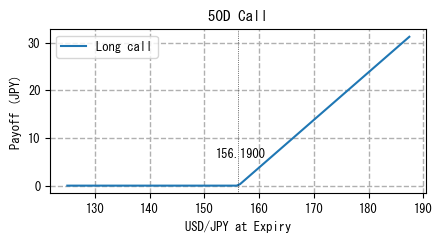

In [2]:
expFX = np.linspace(cSTK*0.8, cSTK*1.2, 100)
cPoff = np.maximum(expFX-cSTK,0)

_,ax = plt.subplots()                   ; ax.set_title('50D Call')
ax.plot(expFX,cPoff,label='Long call')
ax.set_xlabel('USD/JPY at Expiry')      ; ax.set_ylabel('Payoff (JPY)')
vline(ax,cSTK); nbShow(ax,cSTK,(-16,20)) ; lgD(ax); gdShow(ax)

In [3]:
nPA,    nSTP, nSd, mtxPA,    jExpDF                                            =\
100_000, 12,   1,   [],   jCvHDL.discount(expDT) ; print(f'jExpDF:{jExpDF:.6f}')

cPAgn  = gsPathGEN(gkPSc,expYR,nSTP,nSd)
for _ in range(nPA):
  onePA = cPAgn.next().value(); mtxPA.append(list(onePA))
cExpFX = nA(mtxPA)[:,-1] ; print('mtxPA行列:',nA(mtxPA).shape)       # 満期日FXの配列
timeGRD= nA([onePA.time(ii) for ii in range(len(onePA))])            # パスの時間軸

cPoff  = uFC*jExpDF*np.maximum(cExpFX-cSTK,0);  cAMT = np.mean(cPoff)
cSE    = np.std(cPoff,ddof=1)/np.sqrt(nPA)
print(f'(MC)Call円額:{cAMT:,.4f}  (SE:{cSE:,.3f})')

jExpDF:0.996975
mtxPA行列: (100000, 13)
(MC)Call円額:2.7746  (SE:0.013)


In [4]:
nSTP, nPA, nSd, mtxPA   =\
  2,   3,   7,   []

cPAgn  = gsPathGEN(gkPSc,expYR,nSTP,nSd)
for _ in range(nPA):
  onePA = cPAgn.next().value(); mtxPA.append(list(onePA))
cExpFX = nA(mtxPA)[:,-1] ; print('mtxPA行列:',nA(mtxPA).shape,'\n',nA(mtxPA))
timeGRD= nA([onePA.time(ii) for ii in range(len(onePA))])

cPoff  = uFC*jExpDF*np.maximum(cExpFX-cSTK,0) ;   cAMT = np.mean(cPoff)
cSE    = np.std(cPoff,ddof=1)/np.sqrt(nPA)
print(f'\n(MC)Call円額:{cAMT:,.4f}  (SE:{cSE:,.3f})')

mtxPA行列: (3, 3) 
 [[157.28    149.64691 145.51392]
 [157.28    160.51924 157.46931]
 [157.28    155.85005 165.50072]]

(MC)Call円額:3.5193  (SE:2.905)


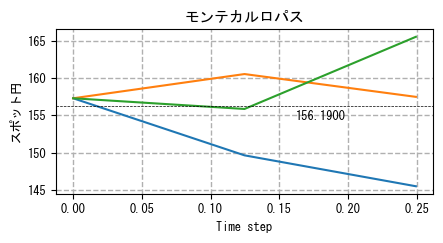

In [5]:
_,ax = plt.subplots()                   ; ax.set_title('モンテカルロパス')
for ii in range(nPA): ax.plot(timeGRD, mtxPA[ii])
ax.set_xlabel('Time step')              ; ax.set_ylabel('スポット円')
hline(ax,cSTK); nbShowY(ax,cSTK,(160,-10)); gdShow(ax)

In [6]:
pSTK,    pVol                                    =\
151.04, 0.1031   ;voHDLp =mu.makeBvol(trdDT,pVol)
                                                          # プロセスとオブジェクト
gkPSp = gkPROC(sQH(jpySP),uCvHDL,jCvHDL,voHDLp) ; gkENGp = anaEE(gkPSp)
pOBJ  = euOPT(vPoff(oPT,pSTK),excE(expDT))      ; setPE(pOBJ, gkENGp)
print(f'Put価格:{pOBJ.NPV()*uFC:.5f}円/$ (vol:{pVol:.4%}, 満期:{expDT.ISO()})')
print(f'Delta:{pOBJ.delta():.2%}  Gamma:{pOBJ.gamma():.2%}  '
       f'Vega:{pOBJ.vega() :.2f}  thetaPerDay:{pOBJ.thetaPerDay():.4f}'      )

Put価格:1.24419円/$ (vol:10.3100%, 満期:2026-12-25)
Delta:-25.01%  Gamma:3.91%  Vega:24.84  thetaPerDay:-0.0173


In [7]:
pDLT,         pSD,             uExpDF                =\
-0.25,  pVol*np.sqrt(expYR), uCvHDL.discount(expDT)

bdOBJ = ql.BlackDeltaCalculator(oPT,sptDLT,jpySP,jExpDF,uExpDF,pSD)
pSTK = bdOBJ.strikeFromDelta(pDLT); pSTK

151.03847630936812